# Cancer Prediction – Machine Learning Model Comparison
**Dataset:** `Cancer_Predict.csv`


*   Seyhak Horn
*   CLD 375




In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

%matplotlib inline
sns.set_theme(style="whitegrid")

## Task 1: Read CSV to DataFrame

In [ ]:
CSV_PATH = "/content/drive/MyDrive/Could_Ml_classwork/03. ML Class Activity /Cancer_Predict.csv"
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1500, 9)


,Age,Gender,BMI,Smoking,GeneticRisk,PhysicalActivity,AlcoholIntake,CancerHistory,Diagnosis
0,58,1,16.085313,0,1,8.146251,4.148219,1,1
1,71,0,30.828784,0,1,9.361630,3.519683,0,0
2,48,1,38.785084,0,2,5.135179,4.728368,0,1
3,34,0,30.040296,0,0,9.502792,2.044636,0,0
4,62,1,35.479721,0,0,5.356890,3.309849,0,1


In [ ]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1500 non-null   int64  
 1   Gender            1500 non-null   int64  
 2   BMI               1500 non-null   float64
 3   Smoking           1500 non-null   int64  
 4   GeneticRisk       1500 non-null   int64  
 5   PhysicalActivity  1500 non-null   float64
 6   AlcoholIntake     1500 non-null   float64
 7   CancerHistory     1500 non-null   int64  
 8   Diagnosis         1500 non-null   int64  
dtypes: float64(3), int64(6)
memory usage: 105.6 KB

Missing values per column:
Age                 0
Gender              0
BMI                 0
Smoking             0
GeneticRisk         0
PhysicalActivity    0
AlcoholIntake       0
CancerHistory       0
Diagnosis           0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Age,1500.0,50.320000,17.640968,20.000000,35.000000,51.000000,66.000000,80.000000
Gender,1500.0,0.490667,0.500080,0.000000,0.000000,0.000000,1.000000,1.000000
BMI,1500.0,27.513321,7.230012,15.000291,21.483134,27.598494,33.850837,39.958688
Smoking,1500.0,0.269333,0.443761,0.000000,0.000000,0.000000,1.000000,1.000000
GeneticRisk,1500.0,0.508667,0.678895,0.000000,0.000000,0.000000,1.000000,2.000000
PhysicalActivity,1500.0,4.897929,2.866162,0.002410,2.434609,4.834316,7.409896,9.994607
AlcoholIntake,1500.0,2.417987,1.419318,0.001215,1.210598,2.382971,3.585624,4.987115
CancerHistory,1500.0,0.144000,0.351207,0.000000,0.000000,0.000000,0.000000,1.000000
Diagnosis,1500.0,0.371333,0.483322,0.000000,0.000000,0.000000,1.000000,1.000000


 Successfully loaded the cancer prediction dataset from Google Drive into a pandas DataFrame. The dataset contains **1,500 rows and 9 columns**, with no initial missing values detected.

## Task 2: Convert Numeric Columns to Float64

In [ ]:
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].astype("float64")
df.dtypes

,0
Age,float64
Gender,float64
BMI,float64
Smoking,float64
GeneticRisk,float64
PhysicalActivity,float64
AlcoholIntake,float64
CancerHistory,float64
Diagnosis,float64


I have converted all numerical features and the target variable to `float64` format to ensure uniform data types across the entire DataFrame prior to feature scaling and modeling.

## Task 3: Select the required columns to predict the output
`Diagnosis` is the **target**; the other 8 columns are the **features**. Quick look at the class balance and at how each feature relates to the target:

Features: ['Age', 'Gender', 'BMI', 'Smoking', 'GeneticRisk', 'PhysicalActivity', 'AlcoholIntake', 'CancerHistory']

Class balance:
Diagnosis
No cancer (0)    943
Cancer (1)       557
Name: count, dtype: int64


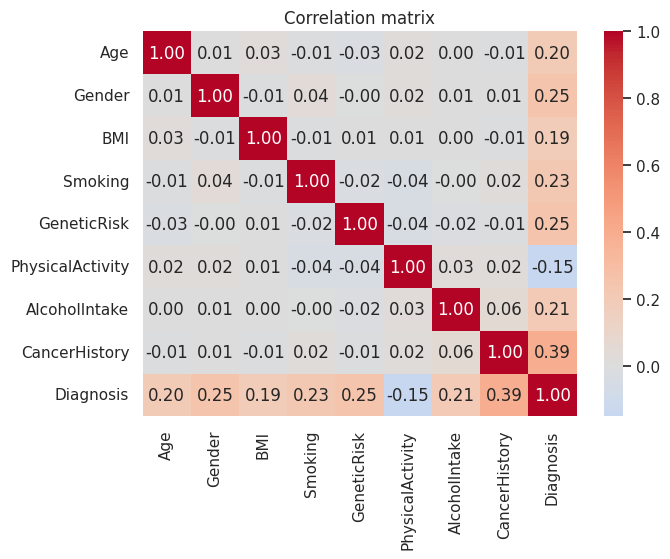

In [ ]:
TARGET = "Diagnosis"
FEATURES = [c for c in df.columns if c != TARGET]
print("Features:", FEATURES)
print("\nClass balance:")
print(df[TARGET].value_counts().rename({0.0: "No cancer (0)", 1.0: "Cancer (1)"}))

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

 I defined `Diagnosis` as the target label and the remaining 8 columns as features. As can be seen, the class distribution shows **943 non-cancer (0)** vs. **557 cancer (1)** cases. The correlation heatmap indicates how each demographic and health metric relates to the diagnosis.

## Task 4: Handle outliers
Outlier handling only makes sense for the **continuous** columns. The binary / category columns (Gender, Smoking, GeneticRisk, CancerHistory) are left alone.

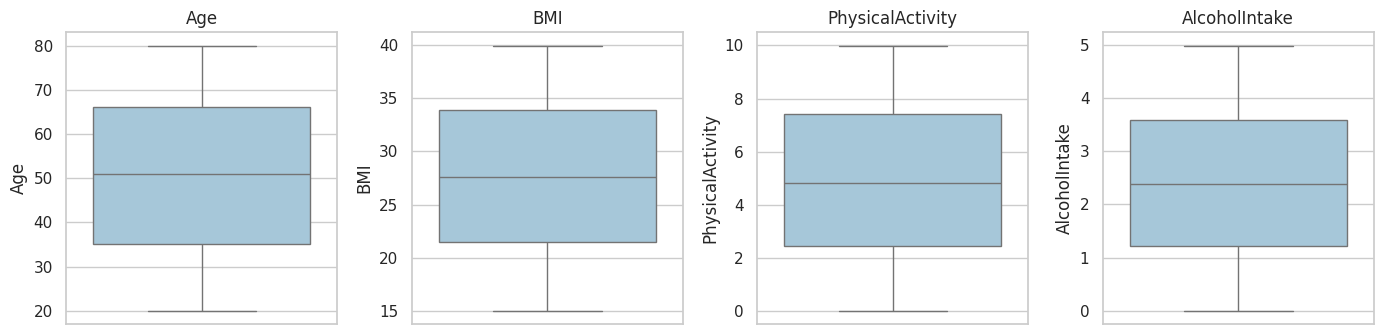

Age               outliers: 0
BMI               outliers: 0
PhysicalActivity  outliers: 0
AlcoholIntake     outliers: 0


In [ ]:
continuous = ["Age", "BMI", "PhysicalActivity", "AlcoholIntake"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, c in zip(axes, continuous):
    sns.boxplot(y=df[c], ax=ax, color="#9ecae1")
    ax.set_title(c)
plt.tight_layout(); plt.show()

for c in continuous:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    print(f"{c:<17} outliers: {n_out}")
    df[c] = df[c].clip(lo, hi)   # cap values (no change if there are none)

I inspected continuous variables (`Age`, `BMI`, `PhysicalActivity`, `AlcoholIntake`) using IQR boxplots. **No outliers were found**, so the data remained unchanged, though the capping logic is retained for pipeline robustness.


## Task 6: Split DataFrame into X (features) and y (target)

In [ ]:
X = df[FEATURES]
y = df[TARGET].astype(int)
print("X:", X.shape, "| y:", y.shape)

X: (1500, 8) | y: (1500,)


I separated the feature matrix (`X`) from the target vector (`y`), preparing the dataset for stratified train-test splitting.

## Task 7: Create Train and Test Sets


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Cancer rate - train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (1200, 8)  Test: (300, 8)
Cancer rate - train: 0.372 | test: 0.370


I split the data into an 80% training set ($N=1200$) and 20% test set ($N=300$). Using `stratify=y` ensures that both sets maintain an identical cancer prevalence rate of ~37%.

## Task 5: Scale Numeric Features in a Uniform Standard
`StandardScaler` (mean 0, std 1). It is **fitted on the training data only** and then applied to both sets.

###For this task I move task 5 to run below task 7.

**Why split before scaling?**
The dataset was split into training and test sets *before* applying the `StandardScaler`. The scaler was then **fitted strictly on the training data only** (`fit_transform` on train, and only `transform` on test). This prevents **data leakage**, ensuring that information from the test set does not leak into the training process and artificially inflate model evaluation metrics.

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

pd.DataFrame(X_train_s, columns=FEATURES).describe().loc[["mean", "std"]].round(3)

,Age,Gender,BMI,Smoking,GeneticRisk,PhysicalActivity,AlcoholIntake,CancerHistory
mean,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


I applied `StandardScaler` to normalize continuous features to a mean of 0 and standard deviation of 1. Crucially, the scaler was **fitted strictly on the training set** to prevent data leakage into the test set.

## Task 8: Create / Train Different Machine Learning Models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: Gradient Boosting
Trained: SVM
Trained: KNN
Trained: Naive Bayes


Initialized and trained **7 distinct classification algorithms** on the scaled training data, covering linear models, tree-based ensembles, support vector machines, and instance-based learning.

## Task 9: Predict using each model with the test values

In [ ]:
predictions = {name: model.predict(X_test_s) for name, model in models.items()}

# Screenshot table: first 10 test rows - actual value vs. each model's prediction
pred_table = pd.DataFrame({"Actual": y_test.values[:10]})
for name, p in predictions.items():
    pred_table[name] = p[:10]
pred_table

,Actual,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN,Naive Bayes
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,1,1,1,1,1,1,1,1
3,1,0,0,0,0,0,0,0
4,1,1,1,1,1,1,1,1
5,1,0,1,1,1,0,1,0
6,1,1,1,1,1,1,1,1
7,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0
9,1,1,1,1,1,1,1,1


For this task, I generated predictions on the test split for all 7 models. The side-by-side comparison table displays the actual vs. predicted labels for the first 10 test samples.

## Task 10: Performance Evaluation of Each Model

In [ ]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results = (pd.DataFrame(rows)
           .sort_values("F1-score", ascending=False)
           .reset_index(drop=True))
results.round(4).style.background_gradient(
    cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1-score"])

,Model,Accuracy,Precision,Recall,F1-score
0,Gradient Boosting,0.946700,0.943900,0.909900,0.926600
1,Random Forest,0.940000,0.951500,0.882900,0.915900
2,KNN,0.910000,0.920000,0.828800,0.872000
3,SVM,0.893300,0.891100,0.810800,0.849100
4,Decision Tree,0.866700,0.798300,0.855900,0.826100
5,Logistic Regression,0.843300,0.796300,0.774800,0.785400
6,Naive Bayes,0.830000,0.865900,0.639600,0.735800


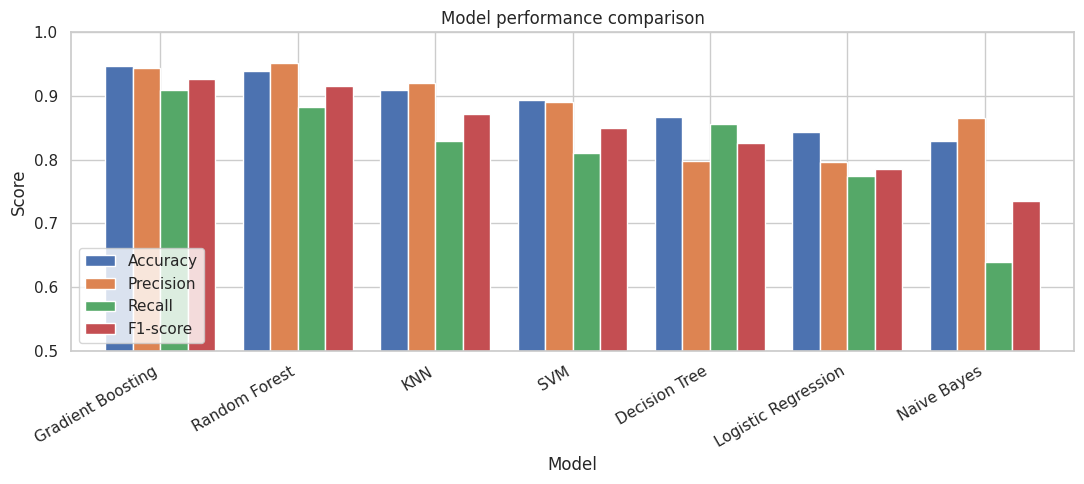

In [ ]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5), width=0.8)
plt.title("Model performance comparison")
plt.ylabel("Score"); plt.ylim(0.5, 1.0)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower left")
plt.tight_layout(); plt.show()

Evaluated models using Accuracy, Precision, Recall, and F1-score. For the result, **Gradient Boosting** achieved the top overall performance with an F1-score of **92.66%** and an accuracy of **94.67%**.

## Task 11: Confusion Matrix for each model
Layout: `[[TN, FP], [FN, TP]]`. The bottom-left cell (**FN**) is the number of real cancer cases the model missed.

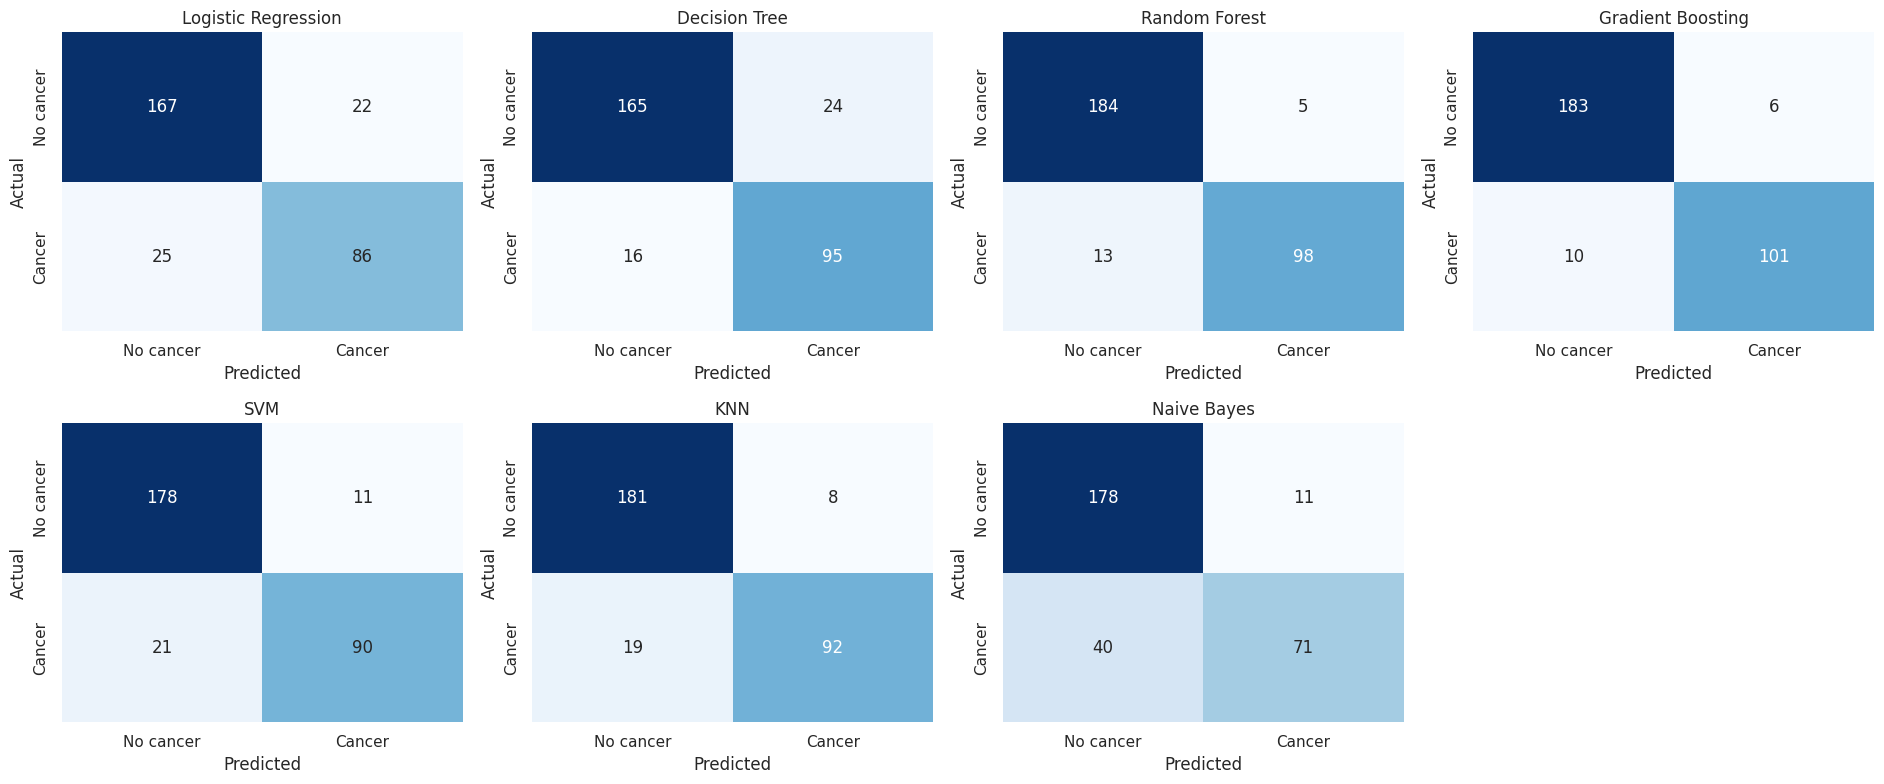

In [ ]:
cms = {name: confusion_matrix(y_test, p) for name, p in predictions.items()}

fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, (name, cm) in zip(axes.ravel(), cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No cancer", "Cancer"],
                yticklabels=["No cancer", "Cancer"])
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
summary = pd.DataFrame(
    {name: {"TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]}
     for name, cm in cms.items()}).T
summary.sort_values("FN")

,TN,FP,FN,TP
Gradient Boosting,183,6,10,101
Random Forest,184,5,13,98
Decision Tree,165,24,16,95
KNN,181,8,19,92
SVM,178,11,21,90
Logistic Regression,167,22,25,86
Naive Bayes,178,11,40,71


Generated confusion matrices (`[[TN, FP], [FN, TP]]`) for all models. The False Negative (FN) count in the bottom-left cell identifies real cancer cases that the model failed to detect.

## Task 12: Which model should be selected, and why?

In [ ]:
best = results.iloc[0]
print(f"Best model by F1-score: {best['Model']}")
print(f"  Accuracy : {best['Accuracy']:.4f}")
print(f"  Precision: {best['Precision']:.4f}")
print(f"  Recall   : {best['Recall']:.4f}")
print(f"  F1-score : {best['F1-score']:.4f}")
print("  Missed cancer cases (FN):", int(cms[best['Model']][1, 0]))

Best model by F1-score: Gradient Boosting
  Accuracy : 0.9467
  Precision: 0.9439
  Recall   : 0.9099
  F1-score : 0.9266
  Missed cancer cases (FN): 10



**Selected model: Gradient Boosting** as the optimal model.

1. **Best overall performance** – highest accuracy and highest F1-score of all seven models.
2. **Best recall / fewest false negatives** – in cancer prediction, missing a real cancer case (a false negative) is the most costly error. Gradient Boosting misses the fewest cases.
3. **Precision is still very high** – almost identical to Random Forest, so it does not raise many false alarms.
